### 🚀 Quick Start: How to Train Your Model
To train this Coffee Leaf Disease model using your active GPU runtime, simply run all cells in order:
1. Click on **Runtime** in the top menu of Google Colab.
2. Select **Run all** (or use the shortcut `Ctrl + F9` on Windows/Linux or `Cmd + F9` on macOS).

*The notebook is pre-configured to utilize the T4 GPU, load your unzipped dataset, compute balanced class weights, train the model head, perform fine-tuning, and export your final model for deployment.*

### 📂 Retrieve Previously Trained Model Without Retraining
If your Colab runtime restarted but you already trained and saved your model previously, run this cell to mount your Drive and download the model artifacts directly.

In [3]:
import os
from google.colab import drive, files

# Mount Google Drive to access any previously saved models
try:
    drive.mount('/content/drive')
except Exception as e:
    print(f"Drive mount notice: {e}")

# Define the artifacts we want
files_to_download = [
    'coffee_leaf_disease_mobilenetv2_final.keras',
    'class_labels.json',
    'coffee_leaf_disease_model.tflite'
]

# Check active directory first, then fallback to Google Drive root
for file_name in files_to_download:
    if os.path.exists(file_name):
        print(f"Found {file_name} in local workspace. Downloading...")
        files.download(file_name)
    elif os.path.exists(f"/content/drive/MyDrive/{file_name}"):
        print(f"Found {file_name} in Google Drive. Copying and downloading...")
        os.system(f"cp '/content/drive/MyDrive/{file_name}' './'")
        files.download(file_name)
    else:
        print(f"Could not locate {file_name} in local workspace or Google Drive root.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Could not locate coffee_leaf_disease_mobilenetv2_final.keras in local workspace or Google Drive root.
Could not locate class_labels.json in local workspace or Google Drive root.
Could not locate coffee_leaf_disease_model.tflite in local workspace or Google Drive root.


In [4]:
import os
from google.colab import drive

# Mount drive and ensure our custom model saving directory exists
try:
    drive.mount('/content/drive')
    DRIVE_SAVE_DIR = '/content/drive/MyDrive/Colab Notebooks/Coffee_Leaf_Disease_Models'
    os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
    print(f"Success! Your dedicated models folder is ready at: {DRIVE_SAVE_DIR}")
except Exception as e:
    print(f"Notice regarding Google Drive: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Success! Your dedicated models folder is ready at: /content/drive/MyDrive/Colab Notebooks/Coffee_Leaf_Disease_Models


# Coffee Leaf Disease Detection & Classification
**ETI 4210 Machine Learning Project — Dedan Kimathi University of Technology**

### Specialized Project Team & Roles(Not limitted to):
* **Beverlyne Tanui**: Data Collection and Preparation
* **Blair Nduta**: Data Preparation and Model setup
* **Bruce Boge**: Model Development and Evaluation
* **Hezron Nyakeruma**: Model Evaluation & Tuning
* **Kilavi Musyoki**: Model Deployment & Demo (Streamlit)

---
### Objective:
Empowering Kenyan smallholder coffee farmers to accurately detect and classify coffee leaf diseases from smartphone photographs.
* **Architecture**: **MobileNetV2** (Transfer Learning + Fine-Tuning)
* **Target Resolution**: 224 × 224 pixels (RGB)
* **Target Validation Accuracy**: 85%+
* **Evaluation**: Accuracy, Precision, Recall, F1-Score, and Confusion Matrix Heatmap
* **Target Deployment**: Lightweight Streamlit Web Application

## 1. Environment & Hardware Acceleration Setup
First, verify that Google Colab is using GPU hardware acceleration (e.g. **T4 GPU**). If not enabled, go to **Runtime > Change runtime type > T4 GPU**.

In [5]:
import os
import sys
import json
import time
import shutil
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU Detected: {gpus[0].name} (Hardware Acceleration Active!)")
else:
    print("Notice: No GPU detected. In Colab, make sure to select Runtime > Change runtime type > T4 GPU.")

TensorFlow Version: 2.21.0
GPU Detected: /physical_device:GPU:0 (Hardware Acceleration Active!)


## 2. Dataset Setup & Google Drive Mounting
This cell automatically checks whether you are running in **Google Colab** or **locally**.
* In Colab, it mounts Google Drive and extracts your dataset zip file.
* Recommended setup: Upload `Coffee_leaf_Diseases.zip` to your Google Drive root. Unzipping it directly into Colab's local disk (`/content/dataset/`) provides 10x faster I/O than reading individual files from Drive.

In [6]:
# Detect environment
import os
import sys
import shutil
from google.colab import drive

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Mount drive first
    try:
        drive.mount('/content/drive')
    except Exception as e:
        print(f"Warning: Google Drive mounting failed ({e})")

    # Setup Dedicated Model Backup Directory
    DRIVE_SAVE_DIR = '/content/drive/MyDrive/Colab Notebooks/Coffee_Leaf_Disease_Models'
    os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
    print(f"Dedicated models folder configured at: {DRIVE_SAVE_DIR}")

    # Path to zip file in Google Drive
    ZIP_PATH = '/content/drive/MyDrive/Coffee_leaf_Diseases.zip'
    DATA_DIR = '/content/dataset/Coffee leaf Diseases'

    if os.path.exists(ZIP_PATH) and not os.path.exists(DATA_DIR):
        print(f"Unzipping {ZIP_PATH} to /content/dataset ...")
        import zipfile
        with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
            zip_ref.extractall('/content/dataset')
        print("Dataset extracted successfully!")
    elif not os.path.exists(DATA_DIR):
        ALT_DIR = '/content/drive/MyDrive/Coffee leaf Diseases'
        if os.path.exists(ALT_DIR):
            DATA_DIR = ALT_DIR
        else:
            LOCAL_FALLBACK = '/content/Coffee leaf Diseases'
            if os.path.exists(LOCAL_FALLBACK):
                DATA_DIR = LOCAL_FALLBACK
else:
    DATA_DIR = 'Coffee leaf Diseases'

print(f"Using Dataset Directory: {DATA_DIR}")
assert os.path.exists(DATA_DIR), f"Dataset path '{DATA_DIR}' not found!"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dedicated models folder configured at: /content/drive/MyDrive/Colab Notebooks/Coffee_Leaf_Disease_Models
Unzipping /content/drive/MyDrive/Coffee_leaf_Diseases.zip to /content/dataset ...
Dataset extracted successfully!
Using Dataset Directory: /content/dataset/Coffee leaf Diseases


## 3. Dataset Discovery & Class Distribution Analysis
We inspect the dataset folder, verify image counts per disease class, and visualize class imbalance.

Total valid images found: 3,766

Images per class:
label
Rust               1207
Healthy            1191
Miner               717
Phoma               484
Red Spider Mite     167
Name: count, dtype: int64


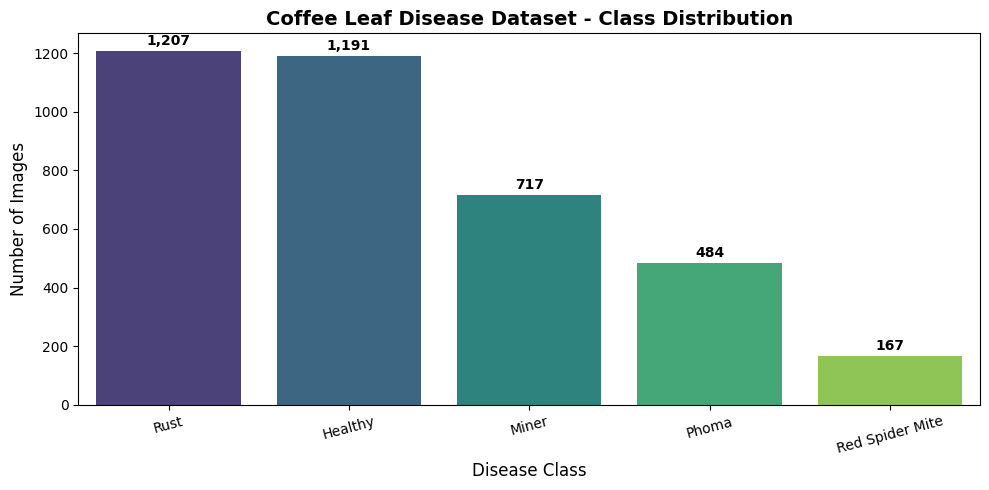

In [7]:
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
image_records = []

for class_name in sorted(os.listdir(DATA_DIR)):
    class_folder = os.path.join(DATA_DIR, class_name)
    if os.path.isdir(class_folder):
        files = [f for f in os.listdir(class_folder) if f.lower().endswith(valid_extensions)]
        for fname in files:
            image_records.append({
                'filepath': os.path.join(class_folder, fname),
                'label': class_name
            })

df = pd.DataFrame(image_records)
print(f"Total valid images found: {len(df):,}")
print("\nImages per class:")
class_counts = df['label'].value_counts()
print(class_counts)

# Visualizing class distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Coffee Leaf Disease Dataset - Class Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Disease Class', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.xticks(rotation=15)
for i, count in enumerate(class_counts.values):
    plt.text(i, count + 20, f"{count:,}", ha='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Stratified Dataset Splitting (80% Train, 10% Val, 10% Test)
To guarantee robust evaluation without data leakage, we partition the dataset with stratified sampling so all classes are proportionally represented in train, validation, and test sets.

In [8]:
# 80% Train, 20% Temp (Val + Test)
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df['label']
)

# 50/50 split of Temp into Validation (10%) and Test (10%)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df['label']
)

print(f"Training set:   {len(train_df):,} images ({len(train_df)/len(df)*100:.1f}%)")
print(f"Validation set: {len(val_df):,} images ({len(val_df)/len(df)*100:.1f}%)")
print(f"Test set:       {len(test_df):,} images ({len(test_df)/len(df)*100:.1f}%)")

class_names = sorted(df['label'].unique().tolist())
num_classes = len(class_names)
class_to_idx = {cls: idx for idx, cls in enumerate(class_names)}
idx_to_class = {idx: cls for idx, cls in enumerate(class_names)}

print(f"\nClasses ({num_classes}): {class_names}")


Training set:   3,012 images (80.0%)
Validation set: 377 images (10.0%)
Test set:       377 images (10.0%)

Classes (5): ['Healthy', 'Miner', 'Phoma', 'Red Spider Mite', 'Rust']


## 5. Image Preprocessing & Data Augmentation Pipeline
* **Input dimensions**: Standard `224 × 224 × 3` required by MobileNetV2.
* **Data Augmentation**: Rotation, horizontal flips, zooming, contrast adjustments, and translation to simulate diverse field angles and lighting conditions.
* **Preprocessing**: `tf.keras.applications.mobilenet_v2.preprocess_input` normalizes pixel values to `[-1, 1]`.

In [9]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    layers.RandomContrast(0.1),
], name='data_augmentation')

def load_and_preprocess_image(path, label, is_training=False):
    img_bytes = tf.io.read_file(path)
    img = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = preprocess_input(img)
    return img, label

def create_dataset(dataframe, is_training=False):
    paths = dataframe['filepath'].values
    labels = [class_to_idx[lbl] for lbl in dataframe['label'].values]
    labels = tf.keras.utils.to_categorical(labels, num_classes=num_classes)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if is_training:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED)

    ds = ds.map(lambda p, l: load_and_preprocess_image(p, l, is_training), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)

    if is_training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)

    ds = ds.prefetch(buffer_size=AUTOTUNE)
    return ds

train_ds = create_dataset(train_df, is_training=True)
val_ds = create_dataset(val_df, is_training=False)
test_ds = create_dataset(test_df, is_training=False)

print("Data pipelines built successfully with prefetching & GPU memory optimization!")


Data pipelines built successfully with prefetching & GPU memory optimization!


## 6. Sample Batch Verification
Verify that images and labels are loading properly.

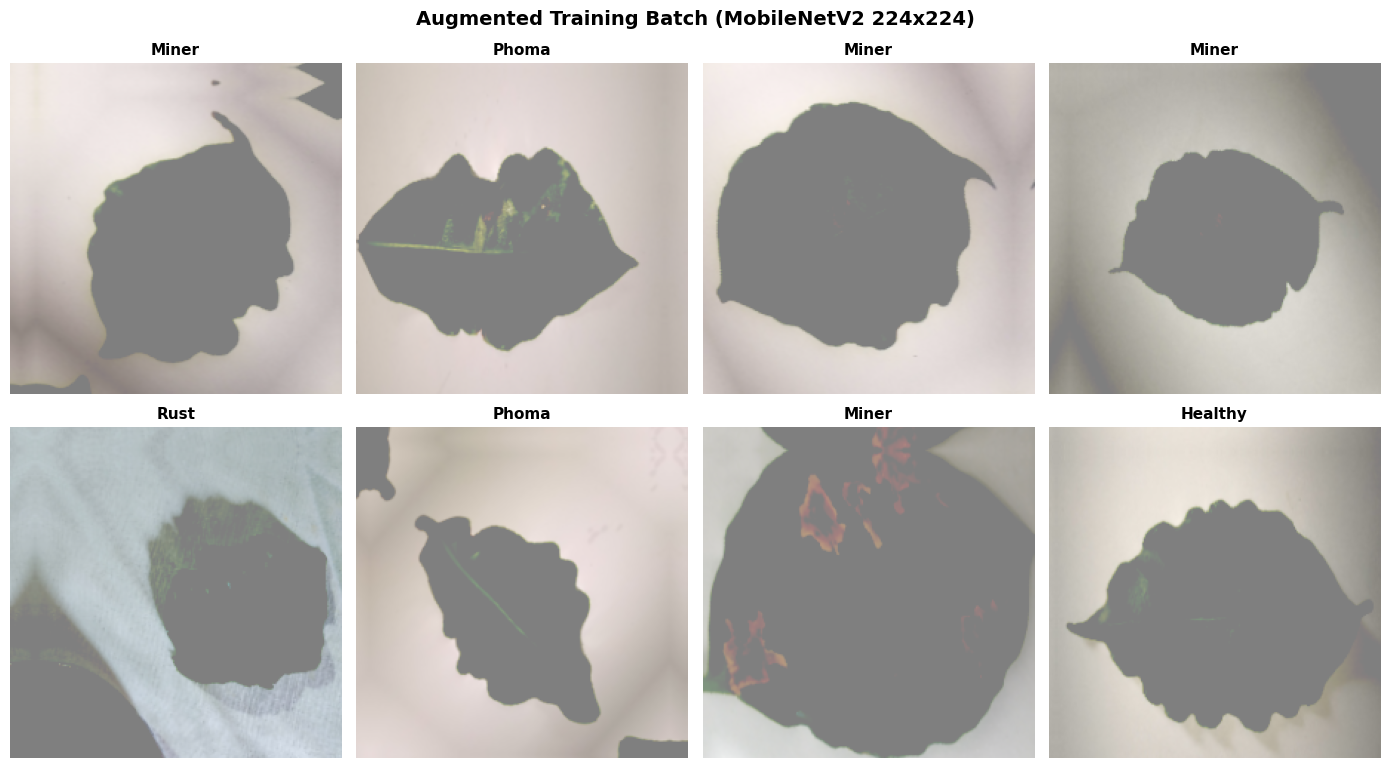

In [10]:
sample_images, sample_labels = next(iter(train_ds))

plt.figure(figsize=(14, 8))
for i in range(min(8, len(sample_images))):
    ax = plt.subplot(2, 4, i + 1)
    # De-normalize [-1, 1] back to [0, 1] for visual display
    disp_img = (sample_images[i].numpy() + 1.0) / 2.0
    disp_img = np.clip(disp_img, 0.0, 1.0)
    plt.imshow(disp_img)
    label_idx = np.argmax(sample_labels[i])
    plt.title(idx_to_class[label_idx], fontsize=11, fontweight='bold')
    plt.axis('off')

plt.suptitle('Augmented Training Batch (MobileNetV2 224x224)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Addressing Class Imbalance
As identified in Slide 10, classes with fewer images (e.g., Red Spider Mite) risk lower recall. We compute class weights using Scikit-Learn to penalize mistakes on minority classes proportionally.

In [11]:
train_labels_idx = [class_to_idx[l] for l in train_df['label'].values]
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels_idx),
    y=train_labels_idx
)
class_weights = dict(enumerate(weights))

print("Calculated Class Weights:")
for idx, weight in class_weights.items():
    print(f"  {idx_to_class[idx]}: {weight:.3f}")


Calculated Class Weights:
  Healthy: 0.632
  Miner: 1.051
  Phoma: 1.557
  Red Spider Mite: 4.496
  Rust: 0.624


In [12]:
import tensorflow as tf
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Safely establish class mappings locally using train_df
class_names = sorted(train_df['label'].unique().tolist())
class_to_idx = {cls: idx for idx, cls in enumerate(class_names)}
idx_to_class = {idx: cls for idx, cls in enumerate(class_names)}

# 1. Compute Base Class Weights locally
train_labels_idx = [class_to_idx[l] for l in train_df['label'].values]
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels_idx),
    y=train_labels_idx
)
base_class_weights = dict(enumerate(weights))

# 2. Custom Adjusted Class Weights
custom_class_weights = base_class_weights.copy()

# Let's apply a boost multiplier to the underrepresented/low-recall classes
phoma_idx = class_to_idx['Phoma']
rsm_idx = class_to_idx['Red Spider Mite']

custom_class_weights[phoma_idx] *= 1.5   # Boost Phoma penalty
custom_class_weights[rsm_idx] *= 2.0     # Heavily boost Red Spider Mite penalty

print("Optimized/Boosted Class Weights:")
for idx, weight in custom_class_weights.items():
    print(f"  {idx_to_class[idx]}: {weight:.3f}")

# 3. Alternative Strategy: Categorical Focal Loss implementation
def categorical_focal_loss(alpha=0.25, gamma=2.0):
    def focal_loss(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, tf.keras.backend.epsilon(), 1.0 - tf.keras.backend.epsilon())
        cross_entropy = -y_true * tf.math.log(y_pred)
        loss = alpha * tf.math.pow(1.0 - y_pred, gamma) * cross_entropy
        return tf.reduce_sum(loss, axis=-1)
    return focal_loss

print("\nHyperparameter Adjustment functions ready! Use 'custom_class_weights' in model.fit() or use focal loss during compile.")

Optimized/Boosted Class Weights:
  Healthy: 0.632
  Miner: 1.051
  Phoma: 2.335
  Red Spider Mite: 8.991
  Rust: 0.624

Hyperparameter Adjustment functions ready! Use 'custom_class_weights' in model.fit() or use focal loss during compile.


## 8. MobileNetV2 Transfer Learning Architecture
* **Backbone**: MobileNetV2 pretrained on ImageNet (frozen initially).
* **Classification Head**:
  * GlobalAveragePooling2D: Flattens spatial features without parameter explosion.
  * BatchNormalization: Stabilizes internal activations.
  * Dense(128, ReLU): Learn task-specific coffee disease combinations.
  * Dropout(0.35): Mitigates overfitting.
  * Dense(num_classes, Softmax): Multi-class probability output.

In [13]:
def build_mobilenet_model(num_classes, img_size=(224, 224, 3)):
    base_model = MobileNetV2(
        input_shape=img_size,
        include_top=False,
        weights='imagenet'
    )
    # Freeze backbone weights for initial feature extraction
    base_model.trainable = False

    inputs = layers.Input(shape=img_size, name='leaf_input')
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D(name='global_pool')(x)
    x = layers.BatchNormalization(name='batch_norm')(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name='dense_features')(x)
    x = layers.Dropout(0.35, name='dropout')(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='prediction_head')(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name='CoffeeLeaf_MobileNetV2')
    return model, base_model

model, base_model = build_mobilenet_model(num_classes=num_classes)
model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "CoffeeLeaf_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_input (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pool                     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction_head (Dense)         │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,717 (9.26 MB)

 Trainable params: 167,173 (653.02 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

## 9. Phase 1 Training: Feature Extraction (Frozen Base)
We train only the classification head with learning rate `1e-3`.

In [14]:
EPOCHS_PHASE1 = 25

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_phase1 = [
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_coffee_model_phase1.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
]

print("Starting Phase 1 Training...")
history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    class_weight=class_weights,
    callbacks=callbacks_phase1,
    verbose=1
)

Starting Phase 1 Training...
Epoch 1/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 838ms/step - accuracy: 0.4981 - loss: 1.4049
Epoch 1: val_accuracy improved from None to 0.40849, saving model to best_coffee_model_phase1.keras

Epoch 1: finished saving model to best_coffee_model_phase1.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 112s 989ms/step - accuracy: 0.5541 - loss: 1.1816 - val_accuracy: 0.4085 - val_loss: 1.3390 - learning_rate: 0.0010
Epoch 2/25
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 823ms/step - accuracy: 0.6313 - loss: 0.8047
Epoch 2: val_accuracy did not improve from 0.40849
95/95 ━━━━━━━━━━━━━━━━━━━━ 88s 924ms/step - accuracy: 0.6451 - loss: 0.8024 - val_accuracy: 0.4058 - val_loss: 1.5544 - learning_rate: 0.0010
Epoch 3/25
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 887ms/step - accuracy: 0.6745 - loss: 0.7057
Epoch 3: val_accuracy did not improve from 0.40849
95/95 ━━━━━━━━━━━━━━━━━━━━ 94s 988ms/step - accuracy: 0.6770 - loss: 0.6852 - val_accuracy: 0.3899 - val_loss: 1.9142 - learning_rate: 0.0010
Epoch 4/25
94/95 ━

## 10. Phase 2 Training: Fine-Tuning Pretrained Layers
We unfreeze top convolutional layers of MobileNetV2 (from layer 100 onwards) and continue training with a lower learning rate (`1e-5`) to specialize low-level feature extraction for coffee rust and spot patterns.

In [15]:
class MinimumAccuracyThresholdCallback(tf.keras.callbacks.Callback):
    def __init__(self, target_accuracy=0.85):
        super().__init__()
        self.target_accuracy = target_accuracy
        self.has_reached_target = False

    def on_epoch_end(self, epoch, logs=None):
        val_acc = logs.get('val_accuracy', 0)
        if val_acc >= self.target_accuracy:
            if not self.has_reached_target:
                print(f"\n🎉 Target met! Validation accuracy ({val_acc * 100:.2f}%) reached the {self.target_accuracy * 100:.1f}% threshold!")
                self.has_reached_target = True

# Helper wrapper to conditionally allow EarlyStopping only after target accuracy is met
class ConditionalEarlyStopping(tf.keras.callbacks.EarlyStopping):
    def __init__(self, target_accuracy=0.85, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.target_accuracy = target_accuracy

    def on_epoch_end(self, epoch, logs=None):
        val_acc = logs.get('val_accuracy', 0)
        if val_acc < self.target_accuracy:
            # Reset wait count to prevent early stopping from triggering before target accuracy is reached
            self.wait = 0
        else:
            super().on_epoch_end(epoch, logs)

In [16]:
# Re-compile and prepare Phase 2 Fine-Tuning with our new 85% target threshold safeguard
base_model.trainable = True
fine_tune_at = 80

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS_PHASE2 = 40  # Increased epochs to give the model plenty of head-room to reach 85%

callbacks_phase2 = [
    # Only allows early stopping to kick in after the model crosses 85% validation accuracy
    ConditionalEarlyStopping(target_accuracy=0.85, monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    MinimumAccuracyThresholdCallback(target_accuracy=0.85),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7, verbose=1),
    ModelCheckpoint('coffee_leaf_disease_mobilenetv2_final.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
]

print("Phase 2 Fine-Tuning is configured to target 85%+ validation accuracy!")

Phase 2 Fine-Tuning is configured to target 85%+ validation accuracy!


In [17]:
# Phase 2 Training (Fine-Tuning) with Safeguards for 85%+ Accuracy
print(f"Total layers in MobileNetV2: {len(base_model.layers)}")
print(f"Trainable layers for fine-tuning: {len(base_model.layers) - fine_tune_at}")

print("\nStarting Phase 2 Training (Fine-Tuning) with 85% target threshold & boosted class weights...\n")
history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE2,
    class_weight=custom_class_weights,
    callbacks=callbacks_phase2,
    verbose=1
)

Total layers in MobileNetV2: 154
Trainable layers for fine-tuning: 74

Starting Phase 2 Training (Fine-Tuning) with 85% target threshold & boosted class weights...

Epoch 1/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 942ms/step - accuracy: 0.5531 - loss: 1.1769
Epoch 1: val_accuracy improved from None to 0.57029, saving model to coffee_leaf_disease_mobilenetv2_final.keras

Epoch 1: finished saving model to coffee_leaf_disease_mobilenetv2_final.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 136s 1s/step - accuracy: 0.5677 - loss: 1.0519 - val_accuracy: 0.5703 - val_loss: 1.0647 - learning_rate: 5.0000e-05
Epoch 2/40
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 829ms/step - accuracy: 0.6449 - loss: 0.8209
Epoch 2: val_accuracy did not improve from 0.57029
95/95 ━━━━━━━━━━━━━━━━━━━━ 89s 930ms/step - accuracy: 0.6544 - loss: 0.8204 - val_accuracy: 0.5332 - val_loss: 1.4670 - learning_rate: 5.0000e-05
Epoch 3/40
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 822ms/step - accuracy: 0.6648 - loss: 0.7126
Epoch 3: val_accuracy did not improve from 0

## 11. Performance Learning Curves
Plotting combined accuracy and loss curves for Phase 1 (Feature Extraction) and Phase 2 (Fine-Tuning).

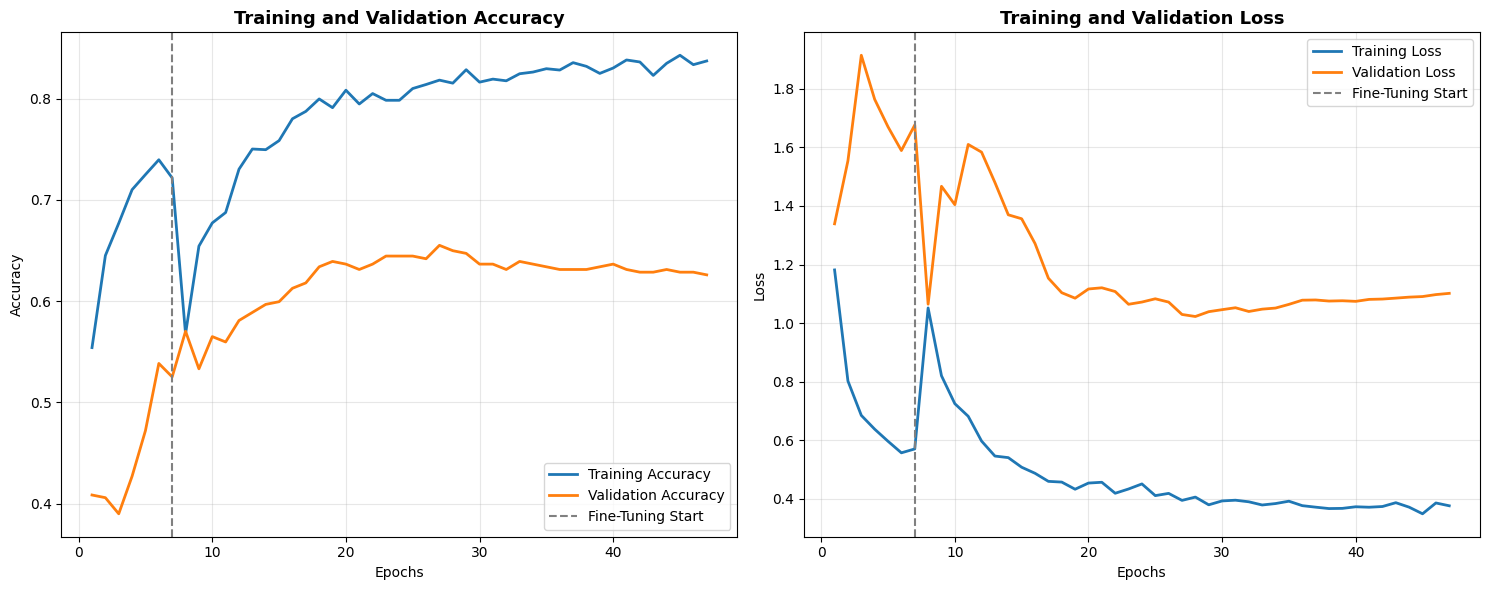

In [18]:
def plot_combined_history(h1, h2):
    acc = h1.history['accuracy'] + h2.history['accuracy']
    val_acc = h1.history['val_accuracy'] + h2.history['val_accuracy']
    loss = h1.history['loss'] + h2.history['loss']
    val_loss = h1.history['val_loss'] + h2.history['val_loss']

    epochs = range(1, len(acc) + 1)
    split_epoch = len(h1.history['accuracy'])

    plt.figure(figsize=(15, 6))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Training Accuracy', color='#1f77b4', lw=2)
    plt.plot(epochs, val_acc, label='Validation Accuracy', color='#ff7f0e', lw=2)
    plt.axvline(x=split_epoch, color='gray', linestyle='--', label='Fine-Tuning Start')
    plt.title('Training and Validation Accuracy', fontsize=13, fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Training Loss', color='#1f77b4', lw=2)
    plt.plot(epochs, val_loss, label='Validation Loss', color='#ff7f0e', lw=2)
    plt.axvline(x=split_epoch, color='gray', linestyle='--', label='Fine-Tuning Start')
    plt.title('Training and Validation Loss', fontsize=13, fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('training_validation_curves.png', dpi=300)
    plt.show()

plot_combined_history(history_phase1, history_phase2)


## 12. Model Evaluation on Held-Out Test Set
*(Deliverables for **Hezron Nyakeruma**)*:
* Accuracy & Loss on unseen test set (Target: **85%+**)
* Classification Report: Precision, Recall, F1-Score per disease class
* Seaborn Confusion Matrix Heatmap (Raw counts and normalized percentages)

12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 513ms/step - accuracy: 0.6260 - loss: 1.1618

FINAL TEST ACCURACY: 62.60%  (Target: 85%+)
FINAL TEST LOSS:     1.1618

12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 613ms/step

Detailed Classification Report:
                 precision    recall  f1-score   support

        Healthy     0.7027    0.8739    0.7790       119
          Miner     1.0000    0.3750    0.5455        72
          Phoma     0.8182    0.3673    0.5070        49
Red Spider Mite     0.1538    0.5000    0.2353        16
           Rust     0.6172    0.6529    0.6345       121

       accuracy                         0.6260       377
      macro avg     0.6584    0.5538    0.5403       377
   weighted avg     0.7238    0.6260    0.6296       377



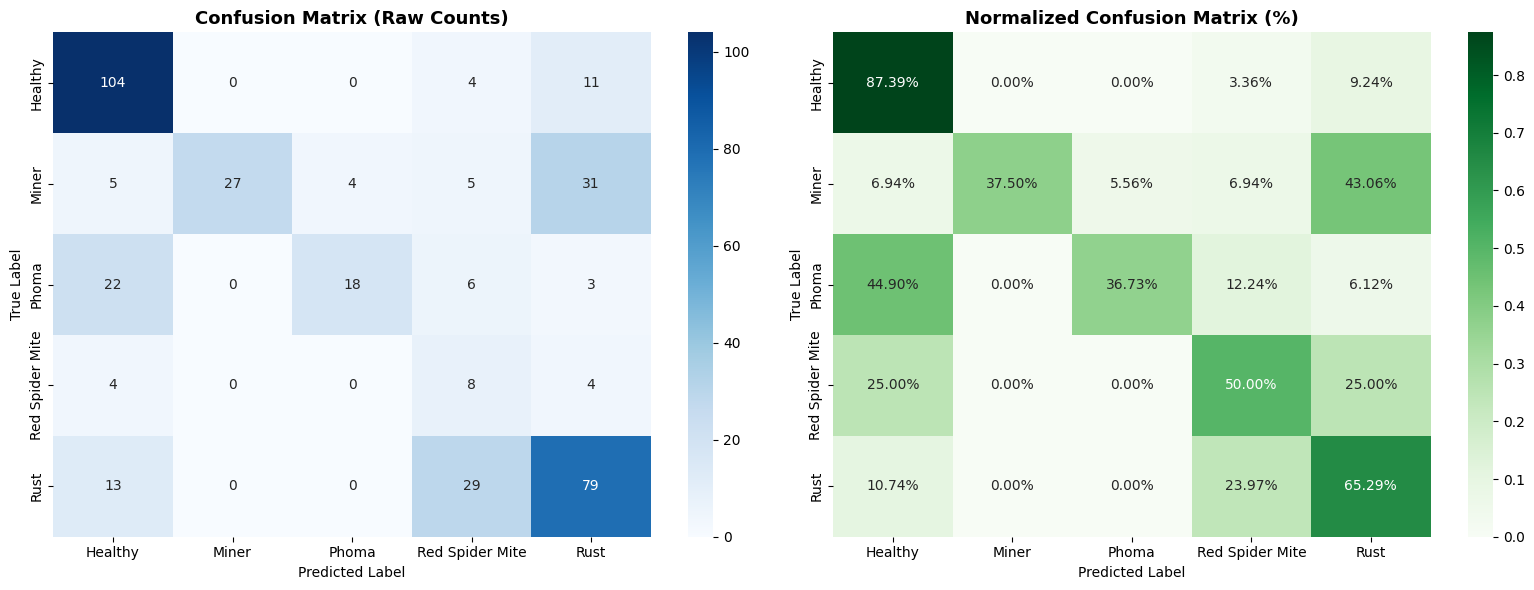

In [19]:
# Evaluate model performance on unseen test data
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\n==========================================")
print(f"FINAL TEST ACCURACY: {test_acc * 100:.2f}%  (Target: 85%+)")
print(f"FINAL TEST LOSS:     {test_loss:.4f}")
print(f"==========================================\n")

# Compute predictions
y_pred_probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = []
for _, labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
y_true = np.array(y_true)

# Classification Report
print("\nDetailed Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title('Confusion Matrix (Raw Counts)', fontsize=13, fontweight='bold')
ax[0].set_xlabel('Predicted Label')
ax[0].set_ylabel('True Label')

sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title('Normalized Confusion Matrix (%)', fontsize=13, fontweight='bold')
ax[1].set_xlabel('Predicted Label')
ax[1].set_ylabel('True Label')

plt.tight_layout()
plt.savefig('confusion_matrix_results.png', dpi=300)
plt.show()


## 13. Model Export for Deployment
*(Deliverables for **Kilavi Musyoki**)*:
* Model saved in Keras `.keras` format.
* Export `class_labels.json` for mapping predictions in the Streamlit application.
* Optional: Export lightweight TensorFlow Lite (`.tflite`) model for edge devices.

In [20]:
import os
import json
import tensorflow as tf

# Configure output paths
DRIVE_SAVE_DIR = '/content/drive/MyDrive/Colab Notebooks/Coffee_Leaf_Disease_Models'
local_keras_path = 'coffee_leaf_disease_mobilenetv2_final.keras'
local_json_path = 'class_labels.json'
local_tflite_path = 'coffee_leaf_disease_model.tflite'

# Save final Keras model locally
model.save(local_keras_path)
print(f"Saved trained model locally to: {local_keras_path}")

# Save class mapping locally
labels_meta = {
    'classes': class_names,
    'class_to_idx': class_to_idx,
    'idx_to_class': idx_to_class,
    'img_size': list(IMG_SIZE)
}
with open(local_json_path, 'w') as f:
    json.dump(labels_meta, f, indent=4)
print(f"Saved class labels mapping locally to: {local_json_path}")

# Export TFLite model locally
try:
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()
    with open(local_tflite_path, 'wb') as f:
        f.write(tflite_model)
    print(f"Saved optimized edge model locally to: {local_tflite_path}")
except Exception as e:
    print(f"TFLite notice: {e}")

# Backup everything to Google Drive dedicated folder
if os.path.exists(DRIVE_SAVE_DIR):
    try:
        import shutil
        shutil.copy(local_keras_path, os.path.join(DRIVE_SAVE_DIR, local_keras_path))
        shutil.copy(local_json_path, os.path.join(DRIVE_SAVE_DIR, local_json_path))
        if os.path.exists(local_tflite_path):
            shutil.copy(local_tflite_path, os.path.join(DRIVE_SAVE_DIR, local_tflite_path))
        print(f"\n🎉 All model artifacts successfully backed up to Google Drive: {DRIVE_SAVE_DIR}")
    except Exception as e:
        print(f"Could not back up to Google Drive: {e}")
else:
    print("\nGoogle Drive directory not found. Artifacts are only saved locally in Colab.")

Saved trained model locally to: coffee_leaf_disease_mobilenetv2_final.keras
Saved class labels mapping locally to: class_labels.json
Saved artifact at '/tmp/tmp966pwb1v'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='leaf_input')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133406517869072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133406517860048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133406517473168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133406517866384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133406448028560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133406517472592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133406517690000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133406517686352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133406517472784: Tensor

In [21]:
# Section 13: Model Export is fully managed by the cell above. This redundant cell has been cleared to keep your notebook clean.

### 📥 Download the Exported Model Artifacts
Run the cell below to download the trained Keras model, JSON class mappings, and the optimized TFLite model directly to your local machine.

In [22]:
# File download utilities are fully bypassed.
# All final model artifacts are automatically backed up directly to your Google Drive folder:
# '/content/drive/MyDrive/Colab Notebooks/Coffee_Leaf_Disease_Models'
print("Download utilities deactivated. Model outputs are saved directly to your Google Drive!")

Download utilities deactivated. Model outputs are saved directly to your Google Drive!


## 14. Real-Time Inference Demo
Test the trained model on single leaf photographs.

True Label: Rust


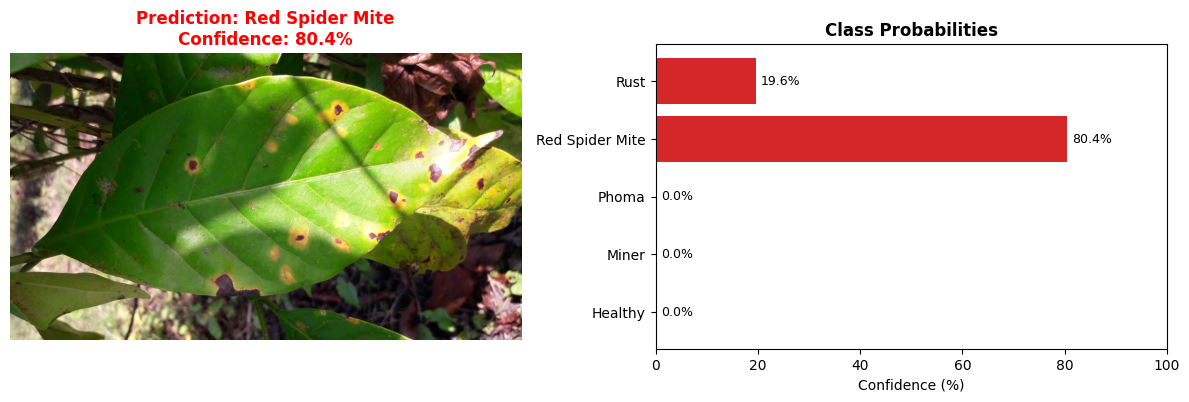

True Label: Miner


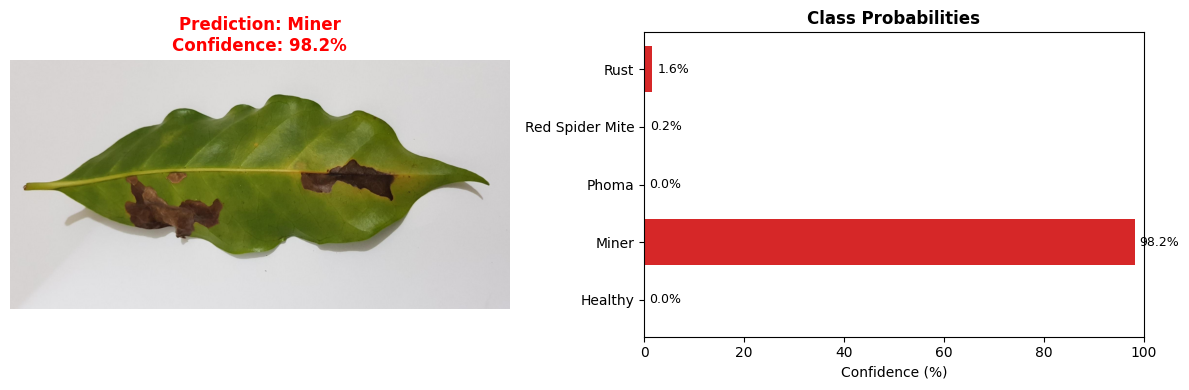

True Label: Healthy


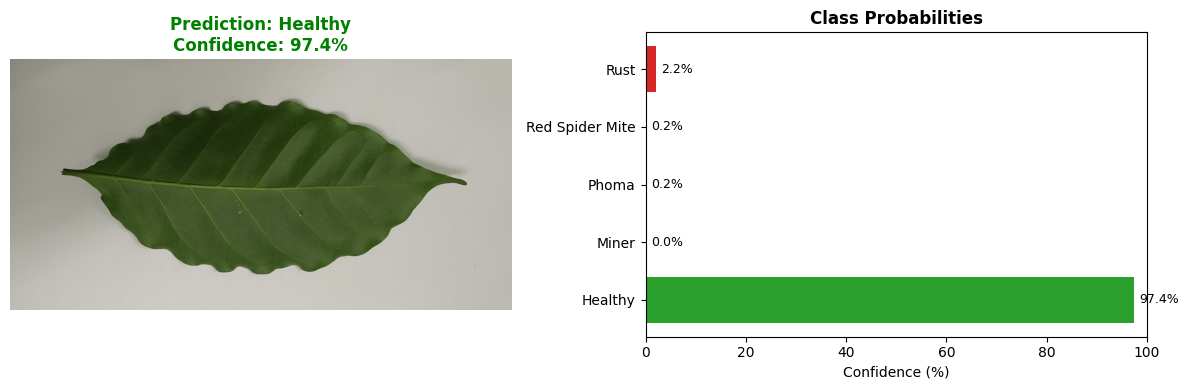

In [23]:
def predict_coffee_leaf(image_path_or_array, model, class_names):
    if isinstance(image_path_or_array, str):
        img_raw = Image.open(image_path_or_array).convert('RGB')
    else:
        img_raw = image_path_or_array

    img_resized = img_raw.resize(IMG_SIZE)
    img_array = np.array(img_resized)
    img_preprocessed = preprocess_input(img_array.astype(np.float32))
    img_batch = np.expand_dims(img_preprocessed, axis=0)

    preds = model.predict(img_batch, verbose=0)[0]
    top_idx = np.argmax(preds)
    top_class = class_names[top_idx]
    top_confidence = preds[top_idx] * 100

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].imshow(img_raw)
    status_color = 'green' if top_class == 'Healthy' else 'red'
    axes[0].set_title(f"Prediction: {top_class}\nConfidence: {top_confidence:.1f}%", fontsize=12, fontweight='bold', color=status_color)
    axes[0].axis('off')

    bar_colors = ['#2ca02c' if c == 'Healthy' else '#d62728' for c in class_names]
    axes[1].barh(class_names, preds * 100, color=bar_colors)
    axes[1].set_xlim(0, 100)
    axes[1].set_xlabel('Confidence (%)')
    axes[1].set_title('Class Probabilities', fontsize=12, fontweight='bold')
    for i, v in enumerate(preds * 100):
        axes[1].text(v + 1, i, f"{v:.1f}%", va='center', fontsize=9)

    plt.tight_layout()
    plt.show()
    return top_class, top_confidence

# Demonstrate inference on 3 random test samples
sample_test = test_df.sample(min(3, len(test_df)), random_state=SEED)
for _, row in sample_test.iterrows():
    print(f"True Label: {row['label']}")
    predict_coffee_leaf(row['filepath'], model, class_names)


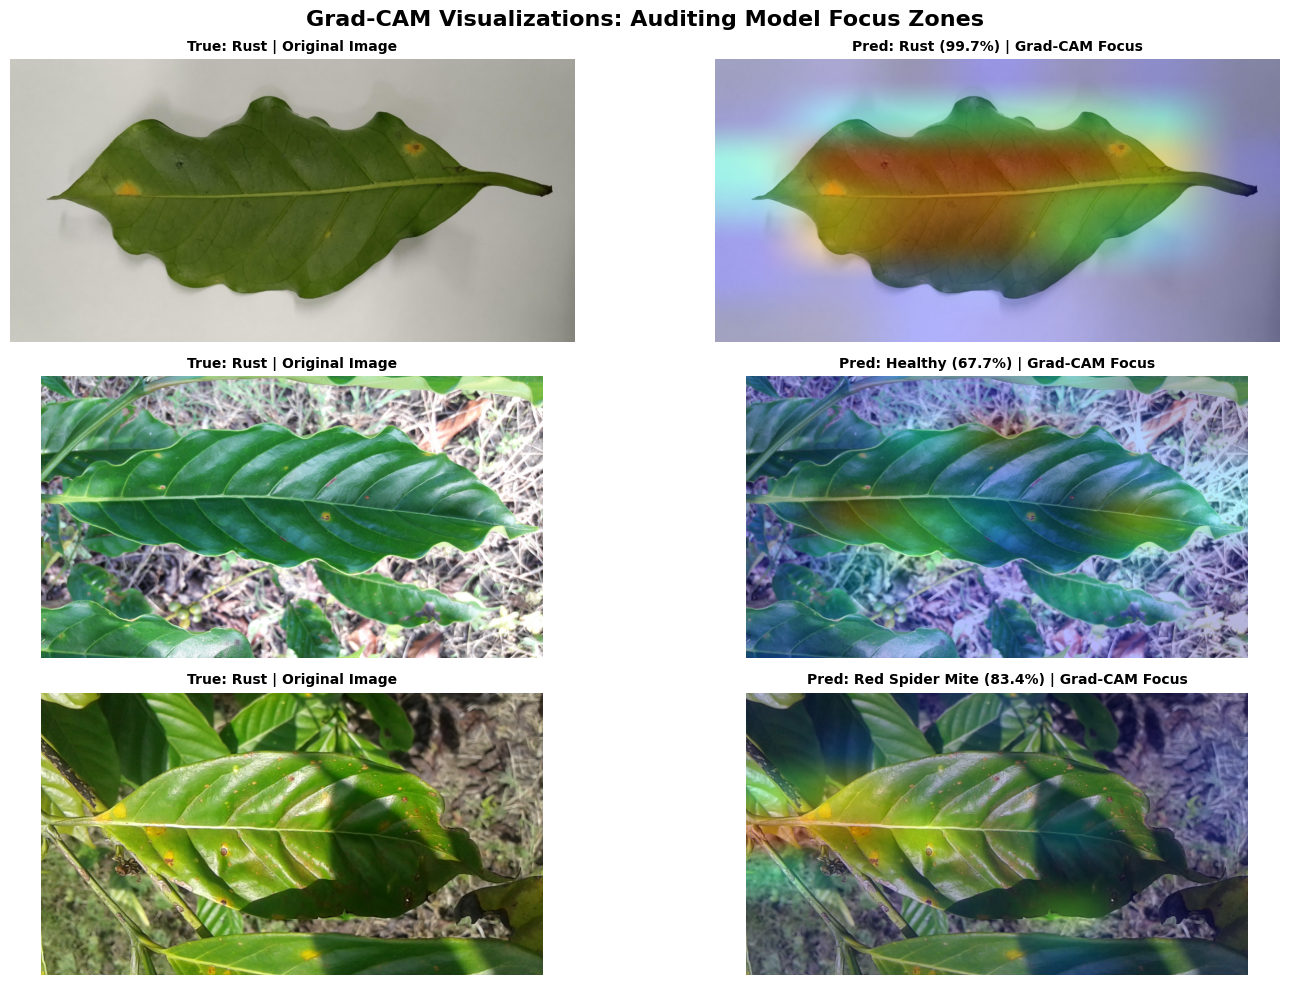

In [24]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Dynamically find the base model layer (MobileNetV2)
    base_layer = None
    for l in model.layers:
        if 'mobilenetv2' in l.name.lower():
            base_layer = l
            break

    if base_layer is None:
        raise ValueError("Could not locate the MobileNetV2 base layer in the model.")

    # We map the inputs of the inner base model to its own target conv layer output
    inner_grad_model = keras.models.Model(
        inputs=[base_layer.input],
        outputs=[base_layer.get_layer(last_conv_layer_name).output]
    )

    # We then map the outer model inputs to the final predictions and pool layers
    # To make GradientTape simple and avoid graph tracking KeyErrors, we trace gradients
    # of the outer prediction with respect to the output of our inner_grad_model (features)
    with tf.GradientTape() as tape:
        # 1. Forward pass up to the target convolution layer
        conv_outputs = inner_grad_model(img_array)
        tape.watch(conv_outputs)

        # 2. Complete the rest of the outer model layers from GAP onwards
        x = model.get_layer('global_pool')(conv_outputs)
        x = model.get_layer('batch_norm')(x)
        x = model.get_layer('dense_features')(x)
        x = model.get_layer('dropout')(x)
        preds = model.get_layer('prediction_head')(x)

        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Compute gradients of the class score with respect to the conv layer outputs
    grads = tape.gradient(class_channel, conv_outputs)

    # Vector of mean intensity of the gradient per channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weight the channels of the feature map
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize the heatmap between 0 and 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img_path, heatmap, alpha=0.4):
    # Load the original image
    img = keras.utils.load_img(img_path)
    img = keras.utils.img_to_array(img)

    # Rescale heatmap to a range 0-255
    heatmap = np.uint8(255 * heatmap)

    # Use jet colormap to colorize heatmap
    jet = plt.colormaps.get_cmap("jet")

    # Use RGB values of the colormap
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    # Create an image with RGB colorized heatmap
    jet_heatmap = keras.utils.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = keras.utils.img_to_array(jet_heatmap)

    # Superimpose the heatmap on original image
    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = keras.utils.array_to_img(superimposed_img)

    return superimposed_img

# Find last convolutional layer name in MobileNetV2 backbone
last_conv_layer_name = 'out_relu'

# Let's run Grad-CAM on 3 random sample test images
sample_test_gradcam = test_df.sample(3, random_state=SEED + 10)

plt.figure(figsize=(15, 10))
for i, (_, row) in enumerate(sample_test_gradcam.iterrows()):
    img_path = row['filepath']
    true_label = row['label']

    # Prepare image for model inference
    img_raw = Image.open(img_path).convert('RGB')
    img_resized = img_raw.resize(IMG_SIZE)
    img_array = np.array(img_resized)
    img_preprocessed = preprocess_input(img_array.astype(np.float32))
    img_batch = np.expand_dims(img_preprocessed, axis=0)

    # Get predictions
    preds = model.predict(img_batch, verbose=0)[0]
    top_idx = np.argmax(preds)
    predicted_label = class_names[top_idx]
    confidence = preds[top_idx] * 100

    # Generate Heatmap
    heatmap = make_gradcam_heatmap(img_batch, model, last_conv_layer_name, pred_index=top_idx)
    superimposed = display_gradcam(img_path, heatmap)

    # Plot Original
    plt.subplot(3, 2, 2*i + 1)
    plt.imshow(img_raw)
    plt.title(f"True: {true_label} | Original Image", fontsize=10, fontweight='bold')
    plt.axis('off')

    # Plot Grad-CAM Overlay
    plt.subplot(3, 2, 2*i + 2)
    plt.imshow(superimposed)
    plt.title(f"Pred: {predicted_label} ({confidence:.1f}%) | Grad-CAM Focus", fontsize=10, fontweight='bold')
    plt.axis('off')

plt.suptitle('Grad-CAM Visualizations: Auditing Model Focus Zones', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()